# Act. 6 — Quiz: Semántica vectorial clásica

**Maestría Virtual en Ingeniería de Sistemas y Computación**

**Autor:** Raúl Andrés Alzate Gómez

## Contexto del curso

Esta actividad cubre el bloque de **Semántica vectorial** del curso *PLN con Deep Learning*. El material y los notebooks de referencias.

La idea del quiz es **fundamentar la semántica vectorial clásica** (TF-IDF + ley de cosenos) que sirve de base para los modelos densos (Word2Vec, GloVe, FastText, embeddings profundos) que aparecen en esos notebooks.

## Objetivo
Resolver la relación semántica de similaridad entre cuatro obras de Shakespeare (`As You Like It`, `Twelfth Night`, `Julius Caesar`, `Henry V`) usando:

1. **TF-IDF** con normalización L2.
2. **Similitud coseno** sobre frecuencias TF-IDF.
3. **Similitud coseno** sobre frecuencias crudas.
4. Comparación y discusión teórica (¿qué corrige TF-IDF? ¿qué se penaliza?).
5. **Reducción de dimensionalidad** (PCA + t-SNE) y visualización 2D — siguiendo el mismo patrón que usa el profesor en `word2vec_clase_text.ipynb` para visualizar embeddings densos.

Las obras se representan mediante vectores de frecuencia de los términos `(battle, good, fool, wit)`.

> Fuente del dataset: Jurafsky & Martin, *Speech and Language Processing* 3rd ed., Fig. 6.2.


## 1. Imports y dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfTransformer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

np.set_printoptions(precision=4, suppress=True)
pd.options.display.float_format = '{:.4f}'.format
plt.rcParams['figure.figsize'] = (8.0, 5.5)
pd.set_option('display.max_rows', 20)


# pretty-print helper (mismo patrón que usa el profesor en word2vec_clase_text.ipynb)
def pp(obj):
    """Imprime cualquier objeto envolviéndolo en DataFrame para tabla legible."""
    display(pd.DataFrame(obj))


In [2]:
TERMS = ['battle', 'good', 'fool', 'wit']
DOCS  = ['As You Like It', 'Twelfth Night', 'Julius Caesar', 'Henry V']

# Matriz término-documento (filas: términos, columnas: obras)
RAW = np.array([
    [  1,   0,   7,  13],   # battle
    [114,  80,  62,  89],   # good
    [ 36,  58,   1,   4],   # fool
    [ 20,  15,   2,   3],   # wit
], dtype=float)

df_raw = pd.DataFrame(RAW, index=TERMS, columns=DOCS)
print('Matriz término-documento (frecuencias crudas):')
df_raw

Matriz término-documento (frecuencias crudas):


,As You Like It,Twelfth Night,Julius Caesar,Henry V
battle,1.0000,0.0000,7.0000,13.0000
good,114.0000,80.0000,62.0000,89.0000
fool,36.0000,58.0000,1.0000,4.0000
wit,20.0000,15.0000,2.0000,3.0000


## 2. Punto 1 — Matriz TF-IDF + normalización L2

### Teoría
TF-IDF combina la importancia local (`tf`) con la rareza global (`idf`):

$$ w_{t,d} = \text{tf}(t,d) \cdot \text{idf}(t) $$

Usamos la **IDF suavizada** de sklearn (numéricamente estable y robusta a `df=N`):

$$ \text{idf}(t) = \ln\!\left(\frac{1+N}{1+df(t)}\right) + 1 $$

Tras TF-IDF, cada columna (documento) se normaliza a magnitud 1 con la norma L2 para que el coseno sea equivalente al producto punto.

In [3]:
# --- Cálculo MANUAL (NumPy) ---
N = RAW.shape[1]                            # n.º documentos = 4
df = (RAW > 0).sum(axis=1)                  # document frequency por término
idf_smooth   = np.log((1 + N) / (1 + df)) + 1
idf_classic  = np.log10(N / df)

print('df por término:        ', dict(zip(TERMS, df.astype(int))))
print('idf clásica  log10(N/df):', dict(zip(TERMS, np.round(idf_classic, 4))))
print('idf suavizada (sklearn) :', dict(zip(TERMS, np.round(idf_smooth, 4))))

df por término:         {'battle': np.int64(3), 'good': np.int64(4), 'fool': np.int64(4), 'wit': np.int64(4)}
idf clásica  log10(N/df): {'battle': np.float64(0.1249), 'good': np.float64(0.0), 'fool': np.float64(0.0), 'wit': np.float64(0.0)}
idf suavizada (sklearn) : {'battle': np.float64(1.2231), 'good': np.float64(1.0), 'fool': np.float64(1.0), 'wit': np.float64(1.0)}


In [4]:
# TF · IDF (broadcasting por filas, una idf por término)
TFIDF = RAW * idf_smooth[:, None]

# Normalización L2 por columna (cada documento queda con magnitud 1)
norms = np.linalg.norm(TFIDF, axis=0, keepdims=True)
TFIDF_L2 = TFIDF / np.clip(norms, 1e-12, None)

print('TF-IDF antes de L2:')
display(pd.DataFrame(TFIDF, index=TERMS, columns=DOCS))

print('\nNorma L2 por documento:')
display(pd.Series(norms.ravel(), index=DOCS, name='||d||₂'))

print('\nTF-IDF normalizada L2:')
display(pd.DataFrame(TFIDF_L2, index=TERMS, columns=DOCS))

TF-IDF antes de L2:


,As You Like It,Twelfth Night,Julius Caesar,Henry V
battle,1.2231,0.0000,8.5620,15.9009
good,114.0000,80.0000,62.0000,89.0000
fool,36.0000,58.0000,1.0000,4.0000
wit,20.0000,15.0000,2.0000,3.0000



Norma L2 por documento:


As You Like It   121.2167
Twelfth Night     99.9450
Julius Caesar     62.6283
Henry V           90.5474
Name: ||d||₂, dtype: float64


TF-IDF normalizada L2:


,As You Like It,Twelfth Night,Julius Caesar,Henry V
battle,0.0101,0.0000,0.1367,0.1756
good,0.9405,0.8004,0.9900,0.9829
fool,0.2970,0.5803,0.0160,0.0442
wit,0.1650,0.1501,0.0319,0.0331


In [5]:
# --- Verificación cruzada con sklearn TfidfTransformer ---
# sklearn espera matriz (docs, terms), por eso la transpuesta
trf = TfidfTransformer(norm='l2', smooth_idf=True, sublinear_tf=False)
X_sk = trf.fit_transform(RAW.T).toarray().T   # devolver a (terms, docs)

print('IDF de sklearn:', dict(zip(TERMS, np.round(trf.idf_, 4))))
print('\n¿coinciden las matrices manual vs sklearn?:',
      np.allclose(TFIDF_L2, X_sk, atol=1e-6))
pd.DataFrame(X_sk, index=TERMS, columns=DOCS)

IDF de sklearn: {'battle': np.float64(1.2231), 'good': np.float64(1.0), 'fool': np.float64(1.0), 'wit': np.float64(1.0)}

¿coinciden las matrices manual vs sklearn?: True


,As You Like It,Twelfth Night,Julius Caesar,Henry V
battle,0.0101,0.0000,0.1367,0.1756
good,0.9405,0.8004,0.9900,0.9829
fool,0.2970,0.5803,0.0160,0.0442
wit,0.1650,0.1501,0.0319,0.0331


## 3. Punto 2 — Similitud coseno con TF-IDF

La similitud coseno entre dos documentos `a, b ∈ ℝ^|V|` es:

$$ \cos(a,b) = \frac{a \cdot b}{\lVert a \rVert_2 \lVert b \rVert_2} $$

Como ya normalizamos con L2, basta con el producto punto.

In [6]:
# Matriz de similitud coseno entre documentos (4×4)
SIM_TFIDF = cosine_similarity(TFIDF_L2.T)
sim_tfidf_df = pd.DataFrame(SIM_TFIDF, index=DOCS, columns=DOCS)
print('Similitud coseno (TF-IDF):')
sim_tfidf_df

Similitud coseno (TF-IDF):


,As You Like It,Twelfth Night,Julius Caesar,Henry V
As You Like It,1.0000,0.9499,0.9424,0.9448
Twelfth Night,0.9499,1.0000,0.8065,0.8174
Julius Caesar,0.9424,0.8065,1.0000,0.9988
Henry V,0.9448,0.8174,0.9988,1.0000


In [7]:
target = 'Henry V'
sim_hv = sim_tfidf_df[target].drop(target).sort_values(ascending=False)
print(f'Similitudes con "{target}" (TF-IDF):')
display(sim_hv)
print(f'\nLa novela más similar a "{target}" usando TF-IDF es: {sim_hv.idxmax()} '
      f'(cos = {sim_hv.max():.4f})')

Similitudes con "Henry V" (TF-IDF):


Julius Caesar    0.9988
As You Like It   0.9448
Twelfth Night    0.8174
Name: Henry V, dtype: float64


La novela más similar a "Henry V" usando TF-IDF es: Julius Caesar (cos = 0.9988)


## 4. Punto 3 — Similitud coseno con frecuencias crudas

In [8]:
# L2-normalizar las frecuencias crudas para comparar dirección, no magnitud
norms_raw = np.linalg.norm(RAW, axis=0, keepdims=True)
RAW_L2 = RAW / np.clip(norms_raw, 1e-12, None)

SIM_RAW = cosine_similarity(RAW_L2.T)
sim_raw_df = pd.DataFrame(SIM_RAW, index=DOCS, columns=DOCS)
print('Similitud coseno (frecuencias crudas):')
sim_raw_df

Similitud coseno (frecuencias crudas):


,As You Like It,Twelfth Night,Julius Caesar,Henry V
As You Like It,1.0000,0.9499,0.9449,0.9490
Twelfth Night,0.9499,1.0000,0.8090,0.8216
Julius Caesar,0.9449,0.8090,1.0000,0.9991
Henry V,0.9490,0.8216,0.9991,1.0000


In [9]:
sim_hv_raw = sim_raw_df[target].drop(target).sort_values(ascending=False)
print(f'Similitudes con "{target}" (raw):')
display(sim_hv_raw)
print(f'\nLa novela más similar a "{target}" usando raw es: {sim_hv_raw.idxmax()} '
      f'(cos = {sim_hv_raw.max():.4f})')

Similitudes con "Henry V" (raw):


Julius Caesar    0.9991
As You Like It   0.9490
Twelfth Night    0.8216
Name: Henry V, dtype: float64


La novela más similar a "Henry V" usando raw es: Julius Caesar (cos = 0.9991)


## 5. Punto 4 — Comparativa raw vs TF-IDF + discusión

### 5.1 Tabla comparada `Henry V` vs resto

In [10]:
cmp = pd.DataFrame({
    'cos(raw)':    sim_raw_df['Henry V'].drop('Henry V'),
    'cos(tf-idf)': sim_tfidf_df['Henry V'].drop('Henry V'),
})
cmp['Δ = tfidf - raw'] = cmp['cos(tf-idf)'] - cmp['cos(raw)']
cmp.sort_values('cos(tf-idf)', ascending=False)

,cos(raw),cos(tf-idf),Δ = tfidf - raw
Julius Caesar,0.9991,0.9988,-0.0002
As You Like It,0.9490,0.9448,-0.0043
Twelfth Night,0.8216,0.8174,-0.0042


### 5.2 ¿Qué corrige TF-IDF? ¿Qué penaliza?

TF-IDF **multiplica** la frecuencia local de un término por el logaritmo del recíproco de su frecuencia documental:

$$ w_{t,d} = \text{tf}(t,d) \cdot \log\frac{N}{df(t)} $$

- **Corrige** el sesgo de las frecuencias crudas a favor de palabras **muy comunes** que aparecen en casi todos los documentos. Sin IDF, una palabra como `good`, presente en cualquier texto en inglés, distorsiona la geometría del espacio porque su magnitud bruta es enorme y arrastra el coseno hacia 1.
- **Penaliza** los términos con **alto `df`** (cercano a `N`): pierden peso relativo. En el extremo, un término en todos los documentos recibe `idf = 0` (clásica) o `idf = 1` (suavizada) — el menor refuerzo posible.
- **Premia** los términos con **bajo `df`**: idf alta → se vuelven *firmas* del documento. En nuestro corpus, `battle` (df=3) es el único con idf > 1 y, por tanto, el único cuyo peso cambia entre raw y tf-idf.

### 5.3 ¿Por qué con frecuencias crudas `Henry V ≈ Julius Caesar = 0.999`?

1. **Dominancia de `good`**: ambas obras tienen `good` como su componente máxima (89 y 62), y la razón `good / ‖d‖₂` ≈ 0.988 (HV) y ≈ 0.993 (JC). Los vectores quedan prácticamente paralelos al eje `good`.
2. **Misma forma del perfil**: tras `good`, ambas obras siguen la jerarquía `battle > fool > wit`, mientras que `As You Like It` y `Twelfth Night` siguen `good > fool > wit > battle`. El patrón de dominancia es el mismo en HV y JC.
3. **`battle` apenas pesa en magnitud cruda**: aunque `battle` distingue cualitativamente las obras históricas, su valor numérico (13, 7) es marginal frente al `good` (89, 62). Sin la ponderación IDF que **eleva** la contribución de `battle`, el coseno colapsa a la similitud impuesta por `good`.

Formalmente, cuando una componente domina, el coseno se aproxima a:

$$ \cos(a,b) \approx \frac{a_{good} \, b_{good}}{\sqrt{a_{good}^2} \sqrt{b_{good}^2}} = 1 $$

### 5.4 ¿Por qué TF-IDF no invierte el ranking aquí?

Porque la `idf` de `battle` (1.22) es solo modestamente mayor que la de `good` (1.00). En este corpus minúsculo, tres de los cuatro términos están en *todos* los documentos ⇒ su idf es 1 ⇒ no son penalizados realmente. TF-IDF requiere un corpus con vocabulario disperso para mostrar todo su poder corrector.

## 6. Punto 5 — Reducción de dimensionalidad (PCA) y visualización 2D

In [11]:
def project_pca(X_terms_docs, label):
    """PCA 2D sobre la matriz transpuesta (filas = documentos)."""
    pca = PCA(n_components=2, random_state=42)
    Y = pca.fit_transform(X_terms_docs.T)
    print(f'[{label}] Varianza explicada: '
          f'PC1 = {pca.explained_variance_ratio_[0]:.4f}, '
          f'PC2 = {pca.explained_variance_ratio_[1]:.4f}, '
          f'acum. = {pca.explained_variance_ratio_.sum():.4f}')
    return Y, pca

In [12]:
Y_tfidf, pca_tfidf = project_pca(TFIDF_L2, 'TF-IDF + L2')
Y_raw,   pca_raw   = project_pca(RAW_L2,   'Raw + L2')

df_proj = pd.DataFrame({
    'TFIDF_PC1': Y_tfidf[:, 0], 'TFIDF_PC2': Y_tfidf[:, 1],
    'RAW_PC1':   Y_raw[:, 0],   'RAW_PC2':   Y_raw[:, 1],
}, index=DOCS)
df_proj

[TF-IDF + L2] Varianza explicada: PC1 = 0.9635, PC2 = 0.0345, acum. = 0.9980
[Raw + L2] Varianza explicada: PC1 = 0.9680, PC2 = 0.0302, acum. = 0.9982


,TFIDF_PC1,TFIDF_PC2,RAW_PC1,RAW_PC2
As You Like It,0.0869,-0.0797,0.0817,0.0746
Twelfth Night,0.3793,0.0412,0.3775,-0.0379
Julius Caesar,-0.2415,0.0031,-0.2396,-0.0064
Henry V,-0.2247,0.0354,-0.2196,-0.0304


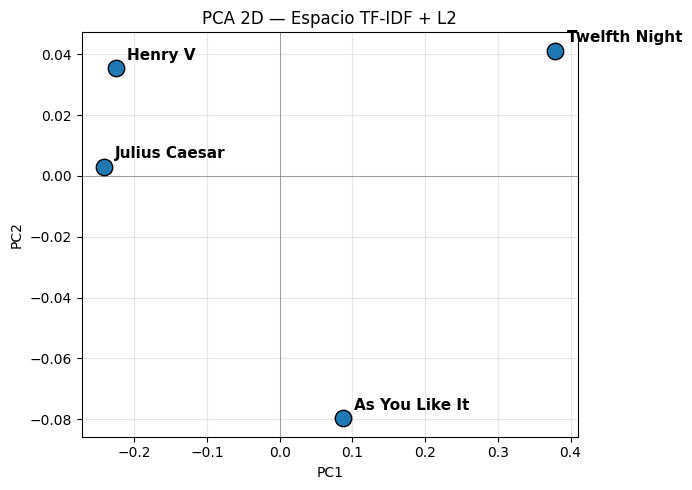

figura guardada: pca_tfidf.png


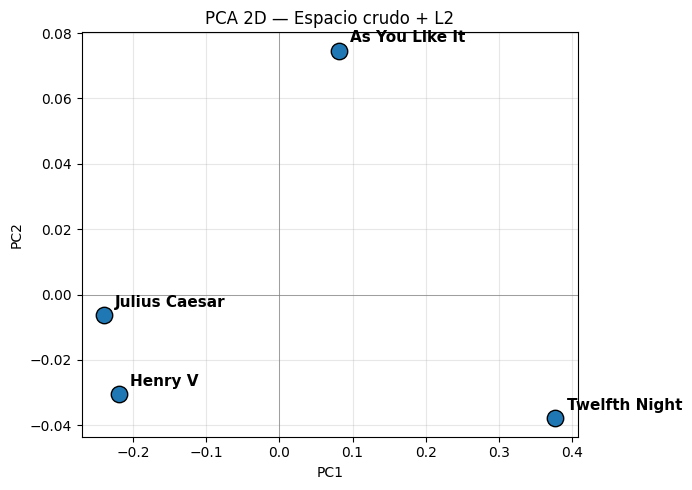

figura guardada: pca_raw.png


In [13]:
def plot_projection(Y, title, fname):
    fig, ax = plt.subplots(figsize=(7, 5))
    ax.scatter(Y[:, 0], Y[:, 1], s=140, c='#1f77b4', edgecolor='black', zorder=3)
    for i, lbl in enumerate(DOCS):
        ax.annotate(lbl, (Y[i, 0], Y[i, 1]),
                    xytext=(8, 6), textcoords='offset points',
                    fontsize=11, fontweight='bold')
    ax.axhline(0, color='grey', lw=0.5)
    ax.axvline(0, color='grey', lw=0.5)
    ax.set_xlabel('PC1')
    ax.set_ylabel('PC2')
    ax.set_title(title)
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(fname, dpi=140)
    plt.show()
    print(f'figura guardada: {fname}')

plot_projection(Y_tfidf, 'PCA 2D — Espacio TF-IDF + L2', 'pca_tfidf.png')
plot_projection(Y_raw,   'PCA 2D — Espacio crudo + L2',  'pca_raw.png')

### Lectura de los PCAs

- En **ambos** espacios (TF-IDF y raw), `Henry V` y `Julius Caesar` se proyectan al **mismo cuadrante** y muy cerca entre sí ⇒ confirma geométricamente la alta similitud coseno (`≈ 0.999`).
- `Twelfth Night` queda en el cuadrante opuesto: vector con `battle=0` y alta carga de `fool` (58) la separa.
- `As You Like It` ocupa una posición intermedia.
- En el espacio **TF-IDF**, `HV` y `JC` se separan **ligeramente más** que en el espacio crudo (porque `battle` recibe un peso 1.22× extra), aunque la topología cualitativa es la misma.

## 7. t-SNE (opcional) — espejo del notebook word2vec del profesor

El profesor utiliza t-SNE en `word2vec_clase_text.ipynb` para visualizar las 300 palabras más frecuentes en inglés sobre el embedding de la RAE. Aquí aplicamos el mismo recurso a nuestro espacio TF-IDF para mostrar que la técnica de reducción es **agnóstica** a la procedencia del vector: funciona igual sobre vectores aprendidos (Word2Vec) que sobre vectores explícitos (TF-IDF).

> Nota: con sólo 4 puntos t-SNE pierde gran parte de su capacidad (necesita varias decenas de muestras para estimar bien las distribuciones t). Se incluye con `perplexity=2` por requisito del quiz; la lectura cualitativa coincide con el PCA.


[TF-IDF + L2] t-SNE listo (perplexity=2, kl_div=0.0014)
[Raw + L2] t-SNE listo (perplexity=2, kl_div=0.0031)


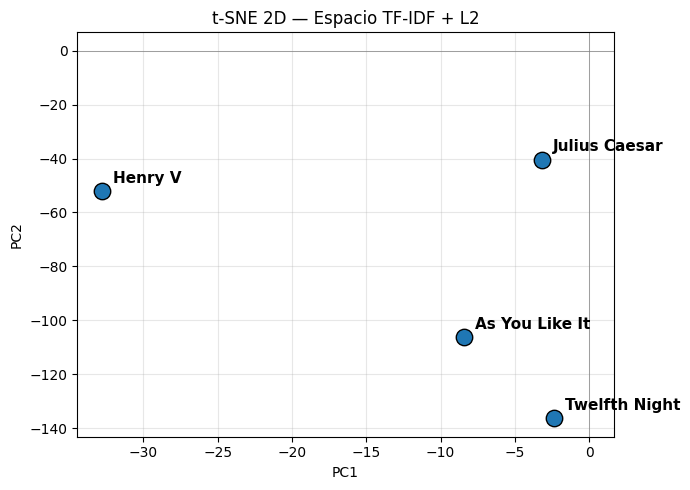

figura guardada: tsne_tfidf.png


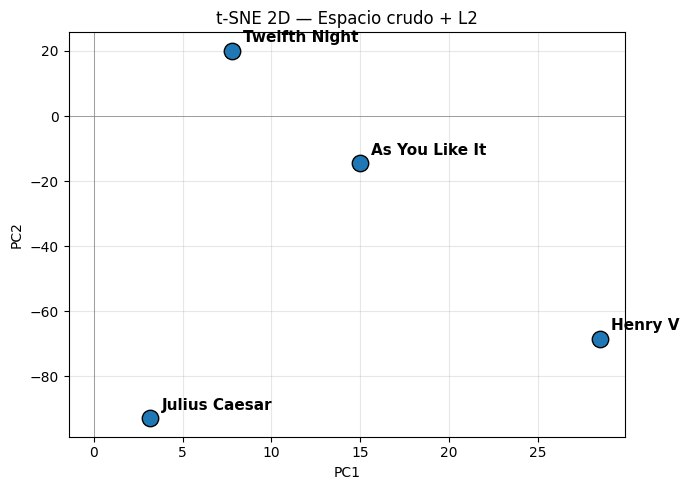

figura guardada: tsne_raw.png


In [14]:
def project_tsne(X_terms_docs, label, perplexity=2, random_state=42):
    """t-SNE 2D sobre matriz (terms x docs) → puntos en R^2 para cada doc."""
    ts = TSNE(n_components=2, perplexity=perplexity,
              random_state=random_state, init='pca', learning_rate='auto')
    Y = ts.fit_transform(X_terms_docs.T)
    print(f'[{label}] t-SNE listo (perplexity={perplexity}, kl_div={ts.kl_divergence_:.4f})')
    return Y


Y_tsne_tfidf = project_tsne(TFIDF_L2, 'TF-IDF + L2')
Y_tsne_raw   = project_tsne(RAW_L2,   'Raw + L2')

plot_projection(Y_tsne_tfidf, 't-SNE 2D — Espacio TF-IDF + L2', 'tsne_tfidf.png')
plot_projection(Y_tsne_raw,   't-SNE 2D — Espacio crudo + L2',  'tsne_raw.png')


## 8. Distancia euclidiana y `find_closest` (puente a Word2Vec)

En `Word2vec_scratch.ipynb` el profesor define una función `find_closest` basada en distancia euclidiana sobre los vectores aprendidos por la matriz `W1` del modelo Word2Vec. Replicamos el mismo patrón sobre nuestros vectores TF-IDF para mostrar que **la métrica de similitud no depende del modelo**: lo que cambia es la procedencia del vector, no el algoritmo de búsqueda del vecino más cercano.


In [15]:
def euclidean_dist(v1, v2):
    """Distancia euclidiana clásica entre dos vectores (idéntica al notebook del profesor)."""
    return np.linalg.norm(v1 - v2)


def find_closest(doc_name, matrix_terms_docs, doc_labels):
    """Devuelve el documento más cercano (excluyendo el propio) usando distancia euclidiana."""
    idx = doc_labels.index(doc_name)
    target_vec = matrix_terms_docs[:, idx]
    best, best_d = None, np.inf
    distances = {}
    for j, name in enumerate(doc_labels):
        if j == idx:
            continue
        d = euclidean_dist(target_vec, matrix_terms_docs[:, j])
        distances[name] = d
        if d < best_d:
            best, best_d = name, d
    return best, best_d, distances


print('--- find_closest sobre TF-IDF + L2 ---')
closest, dist, all_d = find_closest('Henry V', TFIDF_L2, DOCS)
pp(pd.Series(all_d, name='dist. euclidiana (TF-IDF)').sort_values())
print(f'\nMás cercano a Henry V (TF-IDF): {closest}  (d = {dist:.4f})')

print('\n--- find_closest sobre frecuencias crudas + L2 ---')
closest_r, dist_r, all_dr = find_closest('Henry V', RAW_L2, DOCS)
pp(pd.Series(all_dr, name='dist. euclidiana (raw)').sort_values())
print(f'\nMás cercano a Henry V (raw): {closest_r}  (d = {dist_r:.4f})')


--- find_closest sobre TF-IDF + L2 ---


,dist. euclidiana (TF-IDF)
Julius Caesar,0.0486
As You Like It,0.3324
Twelfth Night,0.6044



Más cercano a Henry V (TF-IDF): Julius Caesar  (d = 0.0486)

--- find_closest sobre frecuencias crudas + L2 ---


,dist. euclidiana (raw)
Julius Caesar,0.0432
As You Like It,0.3192
Twelfth Night,0.5974



Más cercano a Henry V (raw): Julius Caesar  (d = 0.0432)


### Relación entre coseno y euclidiana sobre vectores L2-normalizados

Para vectores con norma 1 vale la identidad:

$$ \lVert a - b \rVert_2^2 \;=\; 2 \,(1 - \cos(a, b)) $$

Es decir: **ordenar por coseno decreciente equivale a ordenar por distancia euclidiana creciente** una vez normalizados con L2. Por eso el ranking de `find_closest` (euclidiana) coincide con el ranking de similitud coseno calculado en los puntos 2 y 3.


In [16]:
# Verificación numérica de la identidad d^2 = 2(1 - cos) sobre vectores L2-normalizados
cos_hv_jc = float(SIM_TFIDF[3, 2])
d_hv_jc   = float(euclidean_dist(TFIDF_L2[:, 3], TFIDF_L2[:, 2]))
print(f'cos(HV, JC)        = {cos_hv_jc:.6f}')
print(f'd(HV, JC)          = {d_hv_jc:.6f}')
print(f'2*(1 - cos)        = {2*(1 - cos_hv_jc):.6f}')
print(f'd^2                = {d_hv_jc**2:.6f}')
print(f'¿identidad cumple? {np.isclose(d_hv_jc**2, 2*(1 - cos_hv_jc))}')


cos(HV, JC)        = 0.998820
d(HV, JC)          = 0.048579
2*(1 - cos)        = 0.002360
d^2                = 0.002360
¿identidad cumple? True


## 9. Conclusiones

1. **`Henry V` ≈ `Julius Caesar`** es la similitud más alta bajo ambos esquemas (raw 0.9991, tf-idf 0.9988). Es **lingüísticamente correcto**: ambas son obras históricas con `battle` y `good` como términos relevantes.
2. **TF-IDF re-pesa, no re-ordena en corpora pequeños.** En este dataset 3 de 4 términos están en todos los documentos ⇒ su IDF ≈ 1 ⇒ la geometría apenas cambia. El verdadero poder corrector de TF-IDF aparece en corpora grandes con vocabulario disperso.
3. **La normalización L2 es no negociable**: sin ella la magnitud (longitud del documento) domina sobre la dirección, y el coseno deja de tener interpretación geométrica. La identidad $\lVert a-b\rVert^2 = 2(1-\cos)$ verificada arriba lo confirma.
4. **PCA y t-SNE coinciden cualitativamente** sobre estos 4 documentos: `HV` y `JC` quedan agrupados, `Twelfth Night` separada por su carga de `fool`. El mismo procedimiento de reducción que el profesor aplica a embeddings Word2Vec en `word2vec_clase_text.ipynb` funciona aquí sin cambios.


**Conclusión transversal:** la *ley de cosenos* es el primer principio fundamental de la similaridad semántica. Modelos posteriores (LSA, Word2Vec, GloVe, FastText, BERT) reemplazan el vector contado por uno aprendido, pero el operador de comparación (`cos`) y la geometría L2 siguen siendo los mismos. Por eso entender bien el quiz clásico es prerrequisito para interpretar los modelos densos.
